# Classificação da Qualidade de Vinhos com Machine Learning

## Tech Challenge — FIAP Pós Tech | Fase 2

### Objetivo

Analisar as características físico-químicas de amostras de vinho e identificar padrões associados à qualidade.

A variável `quality` será utilizada para analisar os diferentes níveis de qualidade e, posteriormente, será transformada em uma classificação binária para o modelo de Machine Learning:

- **Alta Qualidade:** `quality >= 7`
- **Baixa/Média Qualidade:** `quality < 7`

### Pergunta central

> **Quais características físico-químicas diferenciam os vinhos de Alta Qualidade (`quality >= 7`) dos vinhos de Baixa/Média Qualidade (`quality < 7`)?**

A comparação entre os dois grupos será utilizada para aprofundar a compreensão dos dados antes da modelagem.


In [1]:
# CARREGAMENTO E PREPARAÇÃO INICIAL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Carregar a base
caminho_base = "../data/WineQT.csv"
df = pd.read_csv(caminho_base)

# Variáveis físico-químicas utilizadas na modelagem
variaveis = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

print(f"Quantidade de amostras: {len(df):,}")
print(f"Quantidade de variáveis físico-químicas: {len(variaveis)}")
print("\nDimensão da base:", df.shape)


Quantidade de amostras: 1,143
Quantidade de variáveis físico-químicas: 11

Dimensão da base: (1143, 13)


In [2]:
# VERIFICAÇÃO DE DADOS FALTANTES

faltantes = df.isnull().sum()

tabela_faltantes = (
    faltantes
    .rename("Valores faltantes")
    .to_frame()
    .query("`Valores faltantes` > 0")
)

if tabela_faltantes.empty:
    print("Não foram identificados valores faltantes na base.")
else:
    display(tabela_faltantes)


Não foram identificados valores faltantes na base.


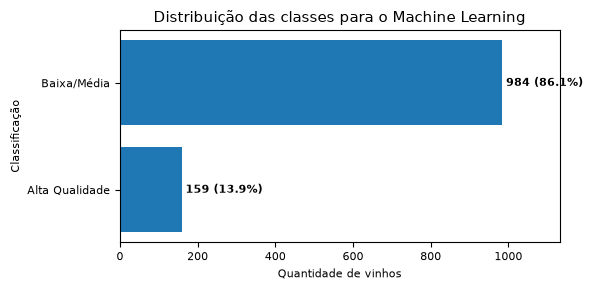

In [3]:
# ==========================================
# DISTRIBUIÇÃO DAS CLASSES
# ==========================================

# Criar a variável alvo binária
df["alta_qualidade"] = (df["quality"] >= 7).astype(int)


# ==========================================
# CRIAR TABELA BINÁRIA
# ==========================================

tabela_binaria = (
    df["alta_qualidade"]
    .value_counts()
    .sort_index()
    .rename_axis("Classe")
    .reset_index(name="Quantidade")
)


# ==========================================
# NOME DAS CLASSES
# ==========================================

tabela_binaria["Classificação"] = tabela_binaria["Classe"].map({
    0: "Baixa/Média",
    1: "Alta Qualidade"
})


# ==========================================
# CALCULAR PERCENTUAL
# ==========================================

tabela_binaria["%"] = (
    tabela_binaria["Quantidade"] / len(df) * 100
)


# ==========================================
# ORGANIZAR TABELA
# ==========================================

tabela_binaria = tabela_binaria[
    ["Classificação", "Quantidade", "%"]
]


# ==========================================
# DADOS DO GRÁFICO
# ==========================================

classes = tabela_binaria["Classificação"]

quantidades = tabela_binaria["Quantidade"]

percentuais = tabela_binaria["%"]


# ==========================================
# INVERTER A ORDEM
# ==========================================

classes = classes.iloc[::-1]
quantidades = quantidades.iloc[::-1]
percentuais = percentuais.iloc[::-1]


# ==========================================
# CRIAÇÃO DO GRÁFICO
# ==========================================

fig, ax = plt.subplots(
    figsize=(6, 3)
)


# ==========================================
# BARRAS HORIZONTAIS
# ==========================================

barras = ax.barh(
    classes,
    quantidades
)


# ==========================================
# TÍTULO
# ==========================================

ax.set_title(
    "Distribuição das classes para o Machine Learning",
    fontsize=11
)


# ==========================================
# EIXOS
# ==========================================

ax.set_xlabel(
    "Quantidade de vinhos",
    fontsize=8
)

ax.set_ylabel(
    "Classificação",
    fontsize=8
)


# ==========================================
# QUANTIDADE + PERCENTUAL
# ==========================================

for barra, quantidade, percentual in zip(
    barras,
    quantidades,
    percentuais
):

    ax.text(
        barra.get_width() + 10,
        barra.get_y() + barra.get_height() / 2,
        f"{quantidade} ({percentual:.1f}%)",
        va="center",
        fontsize=8,
        fontweight="bold"
    )


# ==========================================
# LIMITE DO EIXO X
# ==========================================

ax.set_xlim(
    0,
    max(quantidades) * 1.15
)


# ==========================================
# TAMANHO DOS RÓTULOS
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=8
)


# ==========================================
# AJUSTE
# ==========================================

plt.tight_layout()


# ==========================================
# EXIBIR
# ==========================================

plt.show()

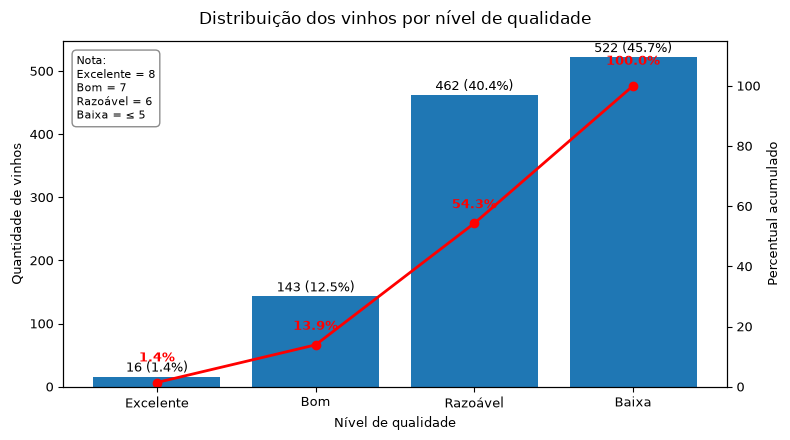

In [4]:
import matplotlib.pyplot as plt


# ==========================================
# CRIAR CATEGORIAS DE QUALIDADE
# ==========================================

df["categoria"] = df["quality"].map({
    8: "Excelente",
    7: "Bom",
    6: "Razoável"
})

df.loc[df["quality"] <= 5, "categoria"] = "Baixa"


# ==========================================
# CRIAR TABELA DE CATEGORIAS
# ==========================================

tabela_categorias = (
    df["categoria"]
    .value_counts()
    .rename_axis("Categoria")
    .reset_index(name="Quantidade")
)


# ==========================================
# ORDEM DAS CATEGORIAS
# ==========================================

ordem_qualidade = [
    "Excelente",
    "Bom",
    "Razoável",
    "Baixa"
]


# ==========================================
# ORGANIZAR OS DADOS
# ==========================================

grafico_qualidade = (
    tabela_categorias
    .set_index("Categoria")
    .loc[ordem_qualidade]
    .reset_index()
)


# ==========================================
# CALCULAR PERCENTUAL INDIVIDUAL
# ==========================================

grafico_qualidade["%"] = (
    grafico_qualidade["Quantidade"]
    / grafico_qualidade["Quantidade"].sum()
    * 100
)


# ==========================================
# PERCENTUAL ACUMULADO
# ==========================================

grafico_qualidade["Acumulado"] = (
    grafico_qualidade["Quantidade"].cumsum()
    / grafico_qualidade["Quantidade"].sum()
    * 100
)


# ==========================================
# CATEGORIAS NO EIXO X
# ==========================================

rotulos = [
    "Excelente",
    "Bom",
    "Razoável",
    "Baixa"
]


# ==========================================
# CRIAÇÃO DO GRÁFICO
# ==========================================

fig, ax1 = plt.subplots(figsize=(8, 4.5))


# ==========================================
# BARRAS
# ==========================================

barras = ax1.bar(
    rotulos,
    grafico_qualidade["Quantidade"]
)


ax1.set_title(
    "Distribuição dos vinhos por nível de qualidade",
    fontsize=12,
    pad=12
)


ax1.set_xlabel(
    "Nível de qualidade",
    fontsize=9
)


ax1.set_ylabel(
    "Quantidade de vinhos",
    fontsize=9
)


# ==========================================
# QUANTIDADE + % INDIVIDUAL
# ==========================================

for barra, quantidade, percentual in zip(
    barras,
    grafico_qualidade["Quantidade"],
    grafico_qualidade["%"]
):

    ax1.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 8,
        f"{quantidade} ({percentual:.1f}%)",
        ha="center",
        fontsize=9
    )


# ==========================================
# LINHA DO ACUMULADO
# ==========================================

ax2 = ax1.twinx()


ax2.plot(
    rotulos,
    grafico_qualidade["Acumulado"],
    marker="o",
    linewidth=2,
    color="red"
)


ax2.set_ylabel(
    "Percentual acumulado",
    fontsize=9
)


ax2.set_ylim(0, 115)


# ==========================================
# PERCENTUAIS ACUMULADOS
# ==========================================

for x, percentual in enumerate(
    grafico_qualidade["Acumulado"]
):

    deslocamento = 7 if x in [0, 3] else 5

    ax2.text(
        x,
        percentual + deslocamento,
        f"{percentual:.1f}%",
        ha="center",
        color="red",
        fontsize=9,
        fontweight="bold"
    )


# ==========================================
# LEGENDA DENTRO DO GRÁFICO
# ==========================================

legenda_notas = (
    "Nota:\n"
    "Excelente = 8\n"
    "Bom = 7\n"
    "Razoável = 6\n"
    "Baixa = ≤ 5"
)


ax1.text(
    0.02,
    0.96,
    legenda_notas,
    transform=ax1.transAxes,
    fontsize=8,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)


# ==========================================
# TAMANHO DOS RÓTULOS
# ==========================================

ax1.tick_params(
    axis="both",
    labelsize=9
)

ax2.tick_params(
    axis="y",
    labelsize=9
)


# ==========================================
# AJUSTE
# ==========================================

plt.tight_layout()


# ==========================================
# EXIBIR
# ==========================================

plt.show()

## Comparação entre vinhos de Baixa/Média e Alta Qualidade

A partir da classificação binária definida para o projeto, os vinhos serão
separados em dois grupos:

- **Alta Qualidade:** `quality >= 7`
- **Baixa/Média Qualidade:** `quality < 7`

A comparação das médias entre esses grupos permite identificar quais
características físico-químicas apresentam maiores diferenças na base.

**Pergunta da análise:**

> **O que diferencia os vinhos de Alta Qualidade dos vinhos de Baixa/Média Qualidade?**


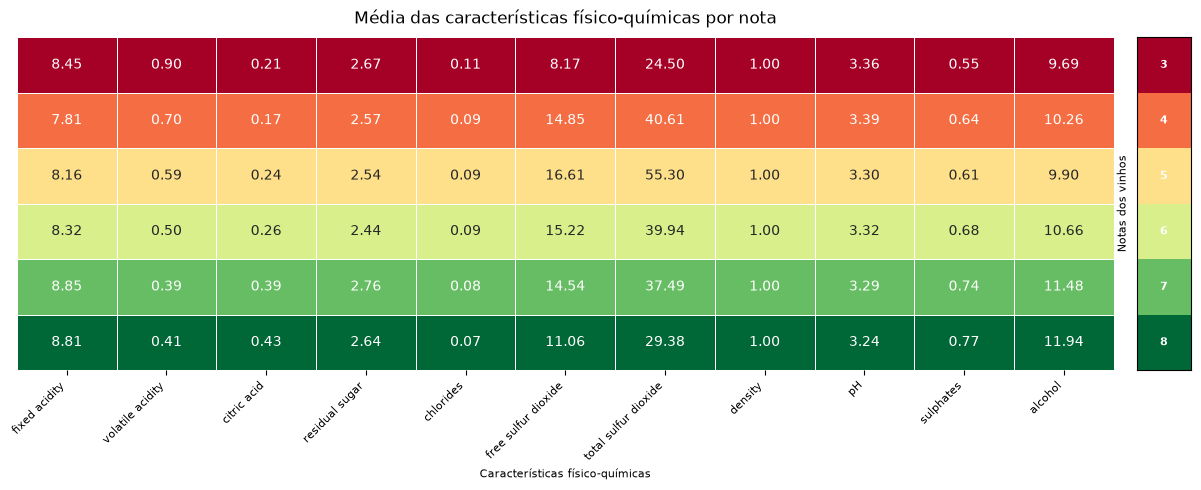

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



# MÉDIAS POR NOTA


variaveis = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]


media_por_nota = (
    df.groupby("quality")[variaveis]
    .mean()
)


# ==========================================
# CORES BASEADAS NA NOTA
# ==========================================

cores = np.tile(
    media_por_nota.index.values.reshape(-1, 1),
    (1, len(variaveis))
)


# ==========================================
# ANOTAÇÕES
# ==========================================

anotacoes = media_por_nota.copy()

for coluna in variaveis:

    anotacoes[coluna] = anotacoes[coluna].map(
        lambda x: f"{x:.2f}"
    )


# ==========================================
# FIGURA
# ==========================================

fig, (ax, cax) = plt.subplots(
    1,
    2,
    figsize=(13.5, 5.2),
    gridspec_kw={
        "width_ratios": [20, 1],
        "wspace": 0.04
    }
)


# ==========================================
# TABELA COLORIDA
# ==========================================

sns.heatmap(
    cores,
    annot=anotacoes.values,
    fmt="",
    cmap="RdYlGn",
    vmin=3,
    vmax=8,
    linewidths=0.5,
    linecolor="white",
    cbar=False,
    ax=ax
)


# ==========================================
# EIXO X
# ==========================================

ax.set_xticklabels(
    variaveis,
    rotation=45,
    ha="right",
    fontsize=8
)

ax.set_yticks([])


# ==========================================
# TÍTULO
# ==========================================

ax.set_title(
    "Média das características físico-químicas por nota",
    fontsize=12,
    pad=10
)

ax.set_xlabel(
    "Características físico-químicas",
    fontsize=8
)

ax.set_ylabel("")


# ==========================================
# RÉGUA DE NOTAS
# ==========================================

notas = np.arange(3, 9)

cax.imshow(
    notas.reshape(-1, 1),
    cmap="RdYlGn",
    vmin=3,
    vmax=8,
    aspect="auto",
    interpolation="nearest",
    origin="upper"
)

cax.set_yticks([])


# ==========================================
# NÚMEROS DA RÉGUA
# ==========================================

for i, nota in enumerate(notas):

    cax.text(
        0,
        i,
        str(nota),
        ha="center",
        va="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )


cax.set_xlim(
    -0.5,
    0.5
)

cax.set_xticks([])


# ==========================================
# TÍTULO DA RÉGUA
# ==========================================

cax.set_ylabel(
    "Notas dos vinhos",
    fontsize=8,
    labelpad=6
)


# ==========================================
# AJUSTE MANUAL
# ==========================================

plt.subplots_adjust(
    left=0.08,
    right=0.95,
    top=0.88,
    bottom=0.24,
    wspace=0.04
)


# ==========================================
# EXIBIR
# ==========================================

plt.show()

In [6]:
import pandas as pd


# ==========================================
# VARIÁVEIS
# ==========================================

variaveis = [
    "citric acid",
    "volatile acidity",
    "residual sugar",
    "chlorides",
    "sulphates",
    "alcohol",
    "fixed acidity",
    "total sulfur dioxide",
    "free sulfur dioxide",
    "pH",
    "density"
]


# ==========================================
# NOMES PARA APRESENTAÇÃO
# ==========================================

nomes = {
    "citric acid": "Ácido cítrico",
    "volatile acidity": "Acidez volátil",
    "residual sugar": "Açúcar residual",
    "chlorides": "Cloretos",
    "sulphates": "Sulfatos",
    "alcohol": "Álcool",
    "fixed acidity": "Acidez fixa",
    "total sulfur dioxide": "SO₂ total",
    "free sulfur dioxide": "SO₂ livre",
    "pH": "pH",
    "density": "Densidade"
}


# ==========================================
# SEPARAR OS GRUPOS DE QUALIDADE
# ==========================================

df_baixa_media = df[df["quality"] < 7]

df_alta = df[df["quality"] >= 7]


# ==========================================
# MÉDIAS
# ==========================================

media_baixa_media = df_baixa_media[variaveis].mean()

media_alta = df_alta[variaveis].mean()


# ==========================================
# MONTAR TABELA
# ==========================================

tabela_comparacao = pd.DataFrame({

    "Característica": variaveis,

    "Média Baixa/Média": media_baixa_media.values,

    "Média Alta Qualidade": media_alta.values,

    "Diferença Média %": (
        (media_alta - media_baixa_media)
        / media_baixa_media
        * 100
    ).values,

    "Direção": [
        "Aumenta" if valor > 0 else "Reduz"
        for valor in (media_alta - media_baixa_media)
    ]
})


# ==========================================
# TRADUZIR NOMES
# ==========================================

tabela_comparacao["Característica"] = (
    tabela_comparacao["Característica"]
    .map(nomes)
)


# ==========================================
# CARACTERÍSTICAS PRINCIPAIS
# ==========================================

destacar = [
    "Ácido cítrico",
    "Acidez volátil",
    "Cloretos",
    "Sulfatos",
    "Álcool"
]


# ==========================================
# DESTAQUE VISUAL
# ==========================================

def destacar_linhas(linha):

    if linha["Característica"] in destacar:

        return [
            "background-color: #FFF2CC; "
            "color: #000000; "
            "font-weight: bold"
        ] * len(linha)

    return [
        "background-color: #F2F2F2; "
        "color: #777777"
    ] * len(linha)


# ==========================================
# FORMATAÇÃO FINAL
# ==========================================

tabela_final = (
    tabela_comparacao
    .style
    .apply(
        destacar_linhas,
        axis=1
    )
    .format({
        "Média Baixa/Média": "{:.2f}",
        "Média Alta Qualidade": "{:.2f}",
        "Diferença Média %": "{:+.1f}%"
    })
)


# ==========================================
# EXIBIR
# ==========================================

tabela_final


,Característica,Média Baixa/Média,Média Alta Qualidade,Diferença Média %,Direção
0,Ácido cítrico,0.25,0.39,+57.4%,Aumenta
1,Acidez volátil,0.55,0.40,-28.6%,Reduz
2,Açúcar residual,2.50,2.75,+10.1%,Aumenta
3,Cloretos,0.09,0.07,-16.0%,Reduz
4,Sulfatos,0.64,0.75,+15.9%,Aumenta
5,Álcool,10.27,11.53,+12.3%,Aumenta
6,Acidez fixa,8.22,8.85,+7.6%,Aumenta
7,SO₂ total,47.41,36.67,-22.6%,Reduz
8,SO₂ livre,15.85,14.19,-10.5%,Reduz
9,pH,3.32,3.28,-1.0%,Reduz


## Análise de dispersão e identificação de possíveis outliers

Antes da etapa de preprocessing, é necessário compreender a dispersão
das variáveis físico-químicas. Para isso, serão analisados valores
mínimos, máximos, média, mediana, quartis e desvio padrão.

Essa análise permite verificar a amplitude das variáveis e identificar
observações potencialmente extremas, que serão posteriormente avaliadas
antes da definição do tratamento dos dados.

In [7]:
# ESTATÍSTICAS DESCRITIVAS

estatisticas = df[variaveis].describe().T
estatisticas["mediana"] = df[variaveis].median()

estatisticas = estatisticas[
    ["min", "25%", "mediana", "mean", "75%", "max", "std"]
]

estatisticas.columns = [
    "Mínimo", "Q1", "Mediana", "Média", "Q3", "Máximo", "Desvio Padrão"
]

estatisticas


,Mínimo,Q1,Mediana,Média,Q3,Máximo,Desvio Padrão
citric acid,0.00000,0.09000,0.25000,0.268364,0.420000,1.00000,0.196686
volatile acidity,0.12000,0.39250,0.52000,0.531339,0.640000,1.58000,0.179633
residual sugar,0.90000,1.90000,2.20000,2.532152,2.600000,15.50000,1.355917
chlorides,0.01200,0.07000,0.07900,0.086933,0.090000,0.61100,0.047267
sulphates,0.33000,0.55000,0.62000,0.657708,0.730000,2.00000,0.170399
alcohol,8.40000,9.50000,10.20000,10.442111,11.100000,14.90000,1.082196
fixed acidity,4.60000,7.10000,7.90000,8.311111,9.100000,15.90000,1.747595
total sulfur dioxide,6.00000,21.00000,37.00000,45.914698,61.000000,289.00000,32.782130
free sulfur dioxide,1.00000,7.00000,13.00000,15.615486,21.000000,68.00000,10.250486
pH,2.74000,3.20500,3.31000,3.311015,3.400000,4.01000,0.156664


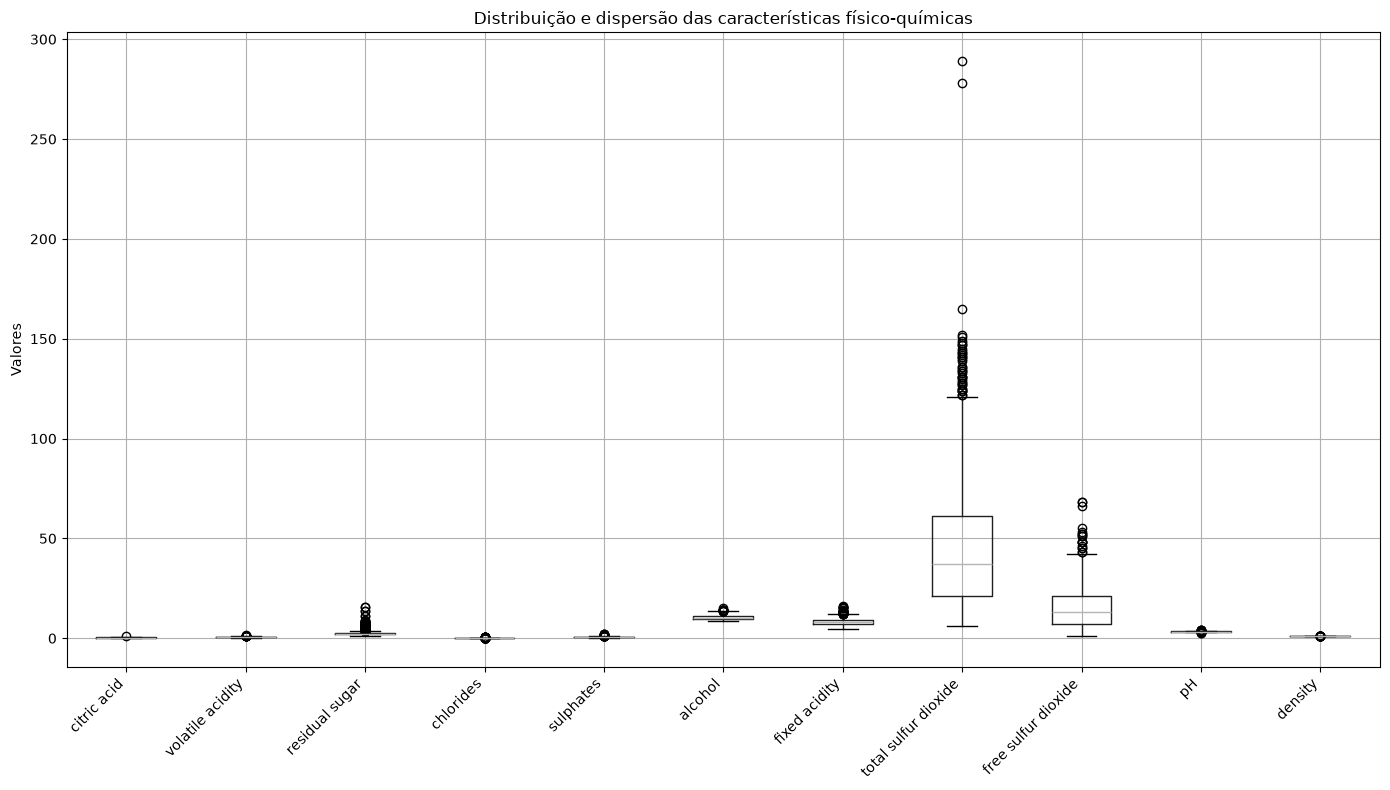

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

df[variaveis].boxplot()

plt.title("Distribuição e dispersão das características físico-químicas")
plt.ylabel("Valores")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [9]:
outliers = []

for coluna in variaveis:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    quantidade = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ).sum()

    percentual = quantidade / len(df) * 100

    outliers.append({
        "Variável": coluna,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Possíveis outliers": quantidade,
        "% dos dados": percentual
    })

tabela_outliers = pd.DataFrame(outliers)

tabela_outliers

,Variável,Q1,Q3,IQR,Limite inferior,Limite superior,Possíveis outliers,% dos dados
0,citric acid,0.09000,0.420000,0.330000,-0.405000,0.915000,1,0.087489
1,volatile acidity,0.39250,0.640000,0.247500,0.021250,1.011250,14,1.224847
2,residual sugar,1.90000,2.600000,0.700000,0.850000,3.650000,110,9.623797
3,chlorides,0.07000,0.090000,0.020000,0.040000,0.120000,77,6.736658
4,sulphates,0.55000,0.730000,0.180000,0.280000,1.000000,43,3.762030
5,alcohol,9.50000,11.100000,1.600000,7.100000,13.500000,12,1.049869
6,fixed acidity,7.10000,9.100000,2.000000,4.100000,12.100000,44,3.849519
7,total sulfur dioxide,21.00000,61.000000,40.000000,-39.000000,121.000000,40,3.499563
8,free sulfur dioxide,7.00000,21.000000,14.000000,-14.000000,42.000000,18,1.574803
9,pH,3.20500,3.400000,0.195000,2.912500,3.692500,20,1.749781


In [10]:
analise_outliers = []

for coluna in variaveis:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    valores_outliers = df.loc[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior),
        coluna
    ]
    
    if len(valores_outliers) > 0:
        analise_outliers.append({
            "Variável": coluna,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Menor outlier": valores_outliers.min(),
            "Maior outlier": valores_outliers.max(),
            "Quantidade": len(valores_outliers)
        })

analise_outliers = pd.DataFrame(analise_outliers)

analise_outliers

,Variável,Limite inferior,Limite superior,Menor outlier,Maior outlier,Quantidade
0,citric acid,-0.405000,0.915000,1.000000,1.00000,1
1,volatile acidity,0.021250,1.011250,1.020000,1.58000,14
2,residual sugar,0.850000,3.650000,3.700000,15.50000,110
3,chlorides,0.040000,0.120000,0.012000,0.61100,77
4,sulphates,0.280000,1.000000,1.010000,2.00000,43
5,alcohol,7.100000,13.500000,13.566667,14.90000,12
6,fixed acidity,4.100000,12.100000,12.200000,15.90000,44
7,total sulfur dioxide,-39.000000,121.000000,122.000000,289.00000,40
8,free sulfur dioxide,-14.000000,42.000000,43.000000,68.00000,18
9,pH,2.912500,3.692500,2.740000,4.01000,20


## Tratamento dos possíveis outliers

A identificação de possíveis outliers foi realizada utilizando o critério de 1,5 × IQR. Foram observados valores extremos em diferentes características físico-químicas.

Como não foram identificadas evidências suficientes de erros ou inconsistências, os valores foram **mantidos** para preservar a variabilidade original da base. Portanto, não foi realizada remoção automática de outliers.


## Análise de correlação

A análise de correlação será utilizada para identificar relações entre
as características físico-químicas dos vinhos e a variável `quality`.

O objetivo é verificar quais características apresentam maior associação
com a qualidade e também identificar possíveis relações entre as próprias
variáveis físico-químicas.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular a matriz de correlação
correlacao = df[variaveis + ["quality"]].corr()

# Exibir a matriz
correlacao

,citric acid,volatile acidity,residual sugar,chlorides,sulphates,alcohol,fixed acidity,total sulfur dioxide,free sulfur dioxide,pH,density,quality
citric acid,1.000000,-0.544187,0.175815,0.245312,0.331232,0.106250,0.673157,0.036871,-0.057589,-0.546339,0.375243,0.240821
volatile acidity,-0.544187,1.000000,-0.005751,0.056336,-0.276079,-0.203909,-0.250728,0.077748,-0.001962,0.221492,0.016512,-0.407394
residual sugar,0.175815,-0.005751,1.000000,0.070863,0.017475,0.058421,0.171831,0.190790,0.165339,-0.116959,0.380147,0.022002
chlorides,0.245312,0.056336,0.070863,1.000000,0.374784,-0.229917,0.107889,0.048163,0.015280,-0.277759,0.208901,-0.124085
sulphates,0.331232,-0.276079,0.017475,0.374784,1.000000,0.094421,0.174592,0.026894,0.034445,-0.185499,0.143139,0.257710
alcohol,0.106250,-0.203909,0.058421,-0.229917,0.094421,1.000000,-0.075055,-0.188165,-0.047095,0.225322,-0.494727,0.484866
fixed acidity,0.673157,-0.250728,0.171831,0.107889,0.174592,-0.075055,1.000000,-0.110628,-0.164831,-0.685163,0.681501,0.121970
total sulfur dioxide,0.036871,0.077748,0.190790,0.048163,0.026894,-0.188165,-0.110628,1.000000,0.661093,-0.059126,0.050175,-0.183339
free sulfur dioxide,-0.057589,-0.001962,0.165339,0.015280,0.034445,-0.047095,-0.164831,0.661093,1.000000,0.072804,-0.054150,-0.063260
pH,-0.546339,0.221492,-0.116959,-0.277759,-0.185499,0.225322,-0.685163,-0.059126,0.072804,1.000000,-0.352775,-0.052453


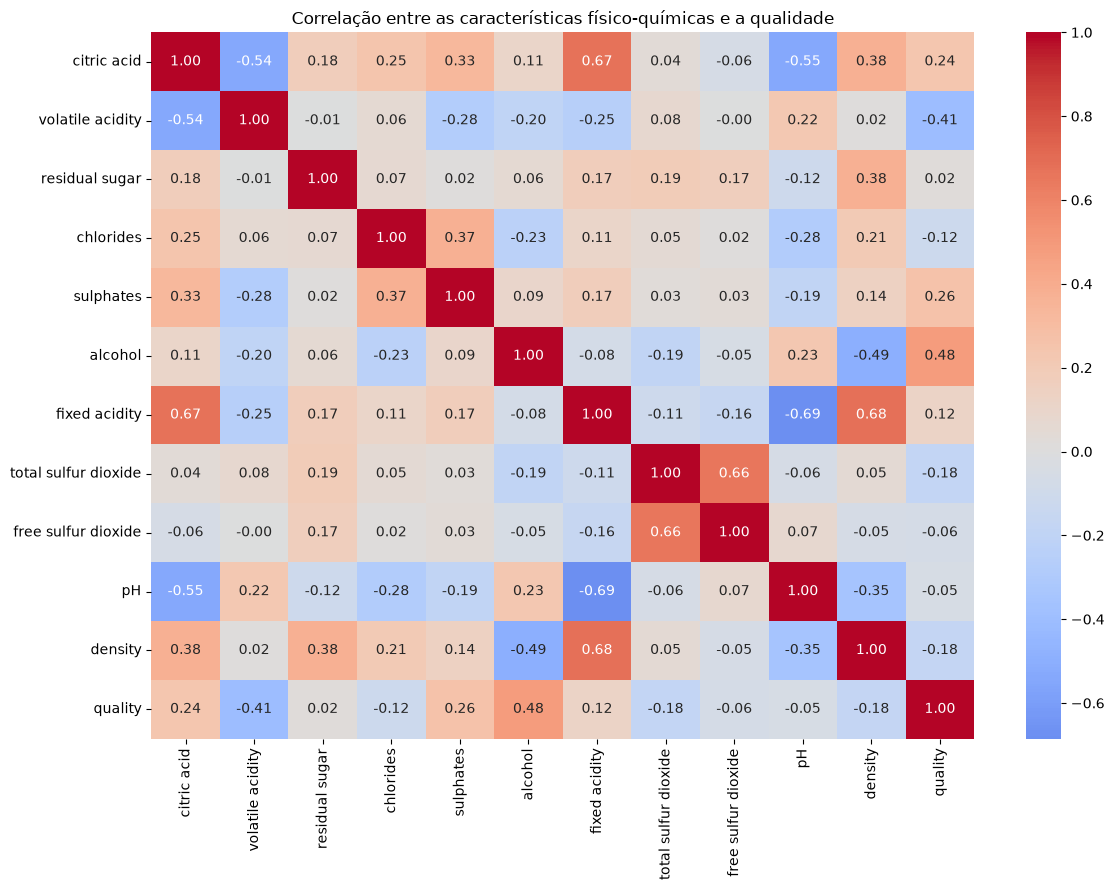

In [12]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlação entre as características físico-químicas e a qualidade")
plt.tight_layout()
plt.show()

### Interpretação

A análise de correlação mostrou que `alcohol` apresentou a maior
correlação positiva com `quality` (0,48), enquanto `volatile acidity`
apresentou a maior correlação negativa (-0,41).

Também foram observadas correlações positivas entre `quality` e
`sulphates` (0,26) e `citric acid` (0,24).

Esses resultados complementam a comparação entre os grupos de
Baixa/Média Qualidade (`quality < 7`) e Alta Qualidade (`quality >= 7`),
na qual são avaliadas as diferenças médias das características
físico-químicas entre as duas classes.

Entre as próprias características físico-químicas, foram observadas
correlações relevantes, como entre `fixed acidity` e `pH` (-0,69),
`fixed acidity` e `density` (0,68) e entre `free sulfur dioxide` e
`total sulfur dioxide` (0,66). Essas relações indicam possível
redundância de informação entre algumas variáveis, aspecto que será
considerado posteriormente na etapa de modelagem.

É importante destacar que correlação representa associação entre as
variáveis e não permite estabelecer relações de causa e efeito.


In [13]:
correlacao_quality = (
    correlacao["quality"]
    .drop("quality")
    .sort_values(ascending=False)
    .to_frame("Correlação com quality")
)

correlacao_quality

,Correlação com quality
alcohol,0.484866
sulphates,0.257710
citric acid,0.240821
fixed acidity,0.121970
residual sugar,0.022002
pH,-0.052453
free sulfur dioxide,-0.063260
chlorides,-0.124085
density,-0.175208
total sulfur dioxide,-0.183339


## Preprocessing

Nesta etapa, os dados serão preparados para a modelagem.

A variável `quality` será utilizada como base para a variável alvo
binária `alta_qualidade`, definida anteriormente:

- `1`: alta qualidade (`quality >= 7`)
- `0`: baixa/média qualidade (`quality < 7`)

A coluna `Id` não será utilizada como variável preditora, pois representa
apenas um identificador da amostra.

In [14]:

# PREPARAÇÃO DOS DADOS PARA MACHINE LEARNING


# Criar variável alvo binária
df["alta_qualidade"] = (
    df["quality"] >= 7
).astype(int)



# VARIÁVEIS PREDITORAS


X = df[variaveis]



# VARIÁVEL ALVO


y = df["alta_qualidade"]



# CONFERÊNCIA DOS DADOS


print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

print("\nDistribuição da variável alvo:")
print(y.value_counts())


# PERCENTUAL DAS CLASSES


print("\nDistribuição percentual:")

print(
    (y.value_counts(normalize=True) * 100)
    .round(2)
)

Formato de X: (1143, 11)
Formato de y: (1143,)

Distribuição da variável alvo:
alta_qualidade
0    984
1    159
Name: count, dtype: int64

Distribuição percentual:
alta_qualidade
0    86.09
1    13.91
Name: proportion, dtype: float64


In [15]:

# DIVISÃO TREINO E TESTE


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# TAMANHO DOS CONJUNTOS

print("Tamanho do conjunto de treino:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTamanho do conjunto de teste:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


# DISTRIBUIÇÃO DAS CLASSES - TREINO


print("\nDistribuição das classes - TREINO:")
print(y_train.value_counts())

print(
    (y_train.value_counts(normalize=True) * 100).round(2)
)


# DISTRIBUIÇÃO DAS CLASSES - TESTE


print("\nDistribuição das classes - TESTE:")
print(y_test.value_counts())

print(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Tamanho do conjunto de treino:
X_train: (914, 11)
y_train: (914,)

Tamanho do conjunto de teste:
X_test: (229, 11)
y_test: (229,)

Distribuição das classes - TREINO:
alta_qualidade
0    787
1    127
Name: count, dtype: int64
alta_qualidade
0    86.11
1    13.89
Name: proportion, dtype: float64

Distribuição das classes - TESTE:
alta_qualidade
0    197
1     32
Name: count, dtype: int64
alta_qualidade
0    86.03
1    13.97
Name: proportion, dtype: float64


In [16]:

# PADRONIZAÇÃO DOS DADOS


from sklearn.preprocessing import StandardScaler


# Criar o scaler
scaler = StandardScaler()


# Aprender os parâmetros SOMENTE com os dados de treino
scaler.fit(X_train)


# Transformar os dados de treino
X_train_scaled = scaler.transform(X_train)


# Transformar os dados de teste
# Sem realizar novo fit
X_test_scaled = scaler.transform(X_test)



# CONFERÊNCIA


print("Formato X_train_scaled:", X_train_scaled.shape)
print("Formato X_test_scaled:", X_test_scaled.shape)



# MÉDIA E DESVIO PADRÃO APÓS PADRONIZAÇÃO


print("\nMédia aproximada das variáveis no treino:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nDesvio padrão aproximado das variáveis no treino:")
print(X_train_scaled.std(axis=0).round(2))

Formato X_train_scaled: (914, 11)
Formato X_test_scaled: (229, 11)

Média aproximada das variáveis no treino:
[-0. -0.  0. -0.  0. -0. -0. -0. -0. -0.  0.]

Desvio padrão aproximado das variáveis no treino:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [17]:
# MODELO 1 - KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("RESULTADOS - KNN")
print("=" * 40)
print(f"Acurácia:  {accuracy_knn:.3f}")
print(f"Precisão:  {precision_knn:.3f}")
print(f"Recall:    {recall_knn:.3f}")
print(f"F1-score:  {f1_knn:.3f}")
print(f"ROC-AUC:   {roc_auc_knn:.3f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nRelatório de classificação:")
print(classification_report(
    y_test, y_pred_knn,
    target_names=["Baixa/Média", "Alta Qualidade"],
    zero_division=0
))


RESULTADOS - KNN
Acurácia:  0.865
Precisão:  0.519
Recall:    0.438
F1-score:  0.475
ROC-AUC:   0.834

Matriz de confusão:
[[184  13]
 [ 18  14]]

Relatório de classificação:
                precision    recall  f1-score   support

   Baixa/Média       0.91      0.93      0.92       197
Alta Qualidade       0.52      0.44      0.47        32

      accuracy                           0.86       229
     macro avg       0.71      0.69      0.70       229
  weighted avg       0.86      0.86      0.86       229



In [18]:

# MODELO 2 - SVM


from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


# CRIAÇÃO DO MODELO


svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)



# TREINAMENTO


svm.fit(
    X_train_scaled,
    y_train
)


# PREVISÃO


y_pred_svm = svm.predict(
    X_test_scaled
)



# PROBABILIDADES


y_prob_svm = svm.predict_proba(
    X_test_scaled
)[:, 1]



# MÉTRICAS

accuracy_svm = accuracy_score(
    y_test,
    y_pred_svm
)

precision_svm = precision_score(
    y_test,
    y_pred_svm,
    zero_division=0
)

recall_svm = recall_score(
    y_test,
    y_pred_svm,
    zero_division=0
)

f1_svm = f1_score(
    y_test,
    y_pred_svm,
    zero_division=0
)

roc_auc_svm = roc_auc_score(
    y_test,
    y_prob_svm
)



# RESULTADOS

print("RESULTADOS - SVM")
print("=" * 40)

print(f"Acurácia:  {accuracy_svm:.3f}")
print(f"Precisão:  {precision_svm:.3f}")
print(f"Recall:    {recall_svm:.3f}")
print(f"F1-score:  {f1_svm:.3f}")
print(f"ROC-AUC:   {roc_auc_svm:.3f}")



# MATRIZ DE CONFUSÃO


print("\nMatriz de confusão:")

print(
    confusion_matrix(
        y_test,
        y_pred_svm
    )
)



# RELATÓRIO DE CLASSIFICAÇÃO

print("\nRelatório de classificação:")

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=[
            "Baixa/Média",
            "Alta Qualidade"
        ],
        zero_division=0
    )
)

RESULTADOS - SVM
Acurácia:  0.900
Precisão:  0.765
Recall:    0.406
F1-score:  0.531
ROC-AUC:   0.850

Matriz de confusão:
[[193   4]
 [ 19  13]]

Relatório de classificação:
                precision    recall  f1-score   support

   Baixa/Média       0.91      0.98      0.94       197
Alta Qualidade       0.76      0.41      0.53        32

      accuracy                           0.90       229
     macro avg       0.84      0.69      0.74       229
  weighted avg       0.89      0.90      0.89       229



c:\Users\Felipe-Pires\OneDrive\Desktop\wine-quality-classification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [19]:

# SVM COM BALANCEAMENTO DAS CLASSES


from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)



# CRIAÇÃO DO MODELO


svm_balanced = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)



# TREINAMENTO


svm_balanced.fit(
    X_train_scaled,
    y_train
)


# PREVISÃO

y_pred_svm_balanced = svm_balanced.predict(
    X_test_scaled
)



# SCORE PARA ROC-AUC


y_score_svm_balanced = svm_balanced.decision_function(
    X_test_scaled
)



# MÉTRICAS


accuracy_svm_balanced = accuracy_score(
    y_test,
    y_pred_svm_balanced
)

precision_svm_balanced = precision_score(
    y_test,
    y_pred_svm_balanced,
    zero_division=0
)

recall_svm_balanced = recall_score(
    y_test,
    y_pred_svm_balanced,
    zero_division=0
)

f1_svm_balanced = f1_score(
    y_test,
    y_pred_svm_balanced,
    zero_division=0
)

roc_auc_svm_balanced = roc_auc_score(
    y_test,
    y_score_svm_balanced
)



# RESULTADOS


print("RESULTADOS - SVM BALANCEADO")
print("=" * 40)

print(f"Acurácia:  {accuracy_svm_balanced:.3f}")
print(f"Precisão:  {precision_svm_balanced:.3f}")
print(f"Recall:    {recall_svm_balanced:.3f}")
print(f"F1-score:  {f1_svm_balanced:.3f}")
print(f"ROC-AUC:   {roc_auc_svm_balanced:.3f}")



# MATRIZ DE CONFUSÃO

print("\nMatriz de confusão:")

print(
    confusion_matrix(
        y_test,
        y_pred_svm_balanced
    )
)



# RELATÓRIO


print("\nRelatório de classificação:")

print(
    classification_report(
        y_test,
        y_pred_svm_balanced,
        target_names=[
            "Baixa/Média",
            "Alta Qualidade"
        ],
        zero_division=0
    )
)

RESULTADOS - SVM BALANCEADO
Acurácia:  0.817
Precisão:  0.411
Recall:    0.719
F1-score:  0.523
ROC-AUC:   0.870

Matriz de confusão:
[[164  33]
 [  9  23]]

Relatório de classificação:
                precision    recall  f1-score   support

   Baixa/Média       0.95      0.83      0.89       197
Alta Qualidade       0.41      0.72      0.52        32

      accuracy                           0.82       229
     macro avg       0.68      0.78      0.70       229
  weighted avg       0.87      0.82      0.84       229



In [20]:
# COMPARAÇÃO DOS MODELOS NO CONJUNTO DE TESTE

comparacao_modelos = pd.DataFrame({
    "Modelo": ["KNN", "SVM", "SVM Balanceado"],
    "Acurácia": [accuracy_knn, accuracy_svm, accuracy_svm_balanced],
    "Precisão - Alta Qualidade": [precision_knn, precision_svm, precision_svm_balanced],
    "Recall - Alta Qualidade": [recall_knn, recall_svm, recall_svm_balanced],
    "F1-score - Alta Qualidade": [f1_knn, f1_svm, f1_svm_balanced],
    "ROC-AUC": [roc_auc_knn, roc_auc_svm, roc_auc_svm_balanced]
})

display(
    comparacao_modelos.style.format({
        "Acurácia": "{:.1%}",
        "Precisão - Alta Qualidade": "{:.1%}",
        "Recall - Alta Qualidade": "{:.1%}",
        "F1-score - Alta Qualidade": "{:.1%}",
        "ROC-AUC": "{:.1%}"
    })
)


,Modelo,Acurácia,Precisão - Alta Qualidade,Recall - Alta Qualidade,F1-score - Alta Qualidade,ROC-AUC
0,KNN,86.5%,51.9%,43.8%,47.5%,83.4%
1,SVM,90.0%,76.5%,40.6%,53.1%,85.0%
2,SVM Balanceado,81.7%,41.1%,71.9%,52.3%,87.0%


## Validação cruzada

Para verificar a consistência dos resultados, os modelos serão comparados com validação cruzada estratificada em 5 folds, utilizando apenas o conjunto de treinamento.

In [21]:
# Validação cruzada estratificada dos modelos

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import pandas as pd

# Configuração do Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modelos
modelos_cv = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "SVM Balanceado": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    )
}

# Métricas utilizadas na validação
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

resultados_cv = []

for nome, modelo in modelos_cv.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", modelo)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=skf,
        scoring=scoring,
        n_jobs=-1
    )

    resultados_cv.append({
        "Modelo": nome,
        "Acurácia média": scores["test_accuracy"].mean(),
        "Precisão média": scores["test_precision"].mean(),
        "Recall médio": scores["test_recall"].mean(),
        "F1 médio": scores["test_f1"].mean(),
        "ROC-AUC médio": scores["test_roc_auc"].mean()
    })

resultados_cv = pd.DataFrame(resultados_cv)

# Formatação percentual
resultados_cv_formatado = resultados_cv.copy()

for coluna in resultados_cv_formatado.columns[1:]:
    resultados_cv_formatado[coluna] = (
        resultados_cv_formatado[coluna] * 100
    ).round(2)

resultados_cv_formatado

,Modelo,Acurácia média,Precisão média,Recall médio,F1 médio,ROC-AUC médio
0,KNN,87.20,56.39,40.25,46.67,83.31
1,SVM,88.19,65.95,32.34,43.31,85.37
2,SVM Balanceado,80.75,40.36,78.83,53.29,88.85


## Seleção do modelo

A validação cruzada estratificada indicou o SVM com balanceamento das classes como o modelo mais adequado ao objetivo do projeto.

O modelo apresentou o maior recall para a classe Alta Qualidade (78,83%), maior F1-score (53,29%) e maior ROC-AUC (88,85%) entre os modelos avaliados.

Embora tenha apresentado menor acurácia geral (80,75%), essa escolha prioriza a identificação da classe minoritária de Alta Qualidade.

## Importância das variáveis

IMPORTÂNCIA DAS VARIÁVEIS


,Variável,Importância média,Desvio
0,alcohol,0.0725,0.0400
1,sulphates,0.0482,0.0346
2,total sulfur dioxide,0.0365,0.0215
3,density,0.0255,0.0158
4,chlorides,0.0198,0.0204
5,volatile acidity,0.0191,0.0439
6,free sulfur dioxide,0.0062,0.0121
7,fixed acidity,0.0032,0.0114
8,residual sugar,-0.0050,0.0169
9,citric acid,-0.0237,0.0168


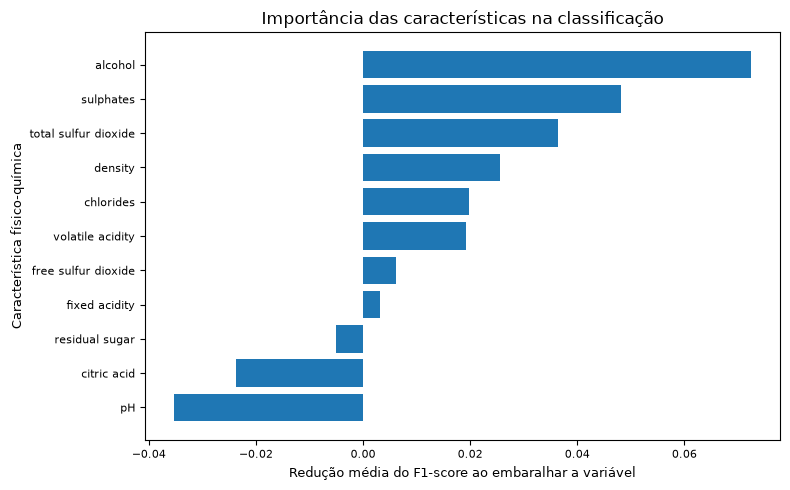

In [22]:

# IMPORTÂNCIA DAS VARIÁVEIS


from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt



# PERMUTATION IMPORTANCE

resultado_importancia = permutation_importance(
    svm_balanced,
    X_test_scaled,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)



# ORGANIZAÇÃO DOS RESULTADOS


importancia = pd.DataFrame({
    "Variável": variaveis,
    "Importância média": resultado_importancia.importances_mean,
    "Desvio": resultado_importancia.importances_std
})


importancia = (
    importancia
    .sort_values(
        "Importância média",
        ascending=False
    )
    .reset_index(drop=True)
)



# EXIBIR TABELA


print("IMPORTÂNCIA DAS VARIÁVEIS")
print("=" * 40)

display(
    importancia.style.format({
        "Importância média": "{:.4f}",
        "Desvio": "{:.4f}"
    })
)



# GRÁFICO

plt.figure(figsize=(8, 5))

plt.barh(
    importancia["Variável"],
    importancia["Importância média"]
)

plt.gca().invert_yaxis()

plt.title(
    "Importância das características na classificação",
    fontsize=12
)

plt.xlabel(
    "Redução média do F1-score ao embaralhar a variável",
    fontsize=9
)

plt.ylabel(
    "Característica físico-química",
    fontsize=9
)

plt.tick_params(
    axis="both",
    labelsize=8
)

plt.tight_layout()

plt.show()

In [23]:

# CORRELAÇÃO x IMPORTÂNCIA DAS VARIÁVEIS


# Correlação das variáveis com a qualidade
correlacao = (
    df[variaveis + ["quality"]]
    .corr()["quality"]
    .drop("quality")
)



# IMPORTÂNCIA DO MODELO


tabela_final_variaveis = pd.DataFrame({
    "Variável": variaveis,
    "Correlação com qualidade": correlacao.values,
    "Importância no modelo": resultado_importancia.importances_mean
})



# ORGANIZAÇÃO


tabela_final_variaveis = (
    tabela_final_variaveis
    .sort_values(
        "Importância no modelo",
        ascending=False
    )
    .reset_index(drop=True)
)



# EXIBIR


display(
    tabela_final_variaveis.style.format({
        "Correlação com qualidade": "{:.3f}",
        "Importância no modelo": "{:.4f}"
    })
)

,Variável,Correlação com qualidade,Importância no modelo
0,alcohol,0.485,0.0725
1,sulphates,0.258,0.0482
2,total sulfur dioxide,-0.183,0.0365
3,density,-0.175,0.0255
4,chlorides,-0.124,0.0198
5,volatile acidity,-0.407,0.0191
6,free sulfur dioxide,-0.063,0.0062
7,fixed acidity,0.122,0.0032
8,residual sugar,0.022,-0.0050
9,citric acid,0.241,-0.0237


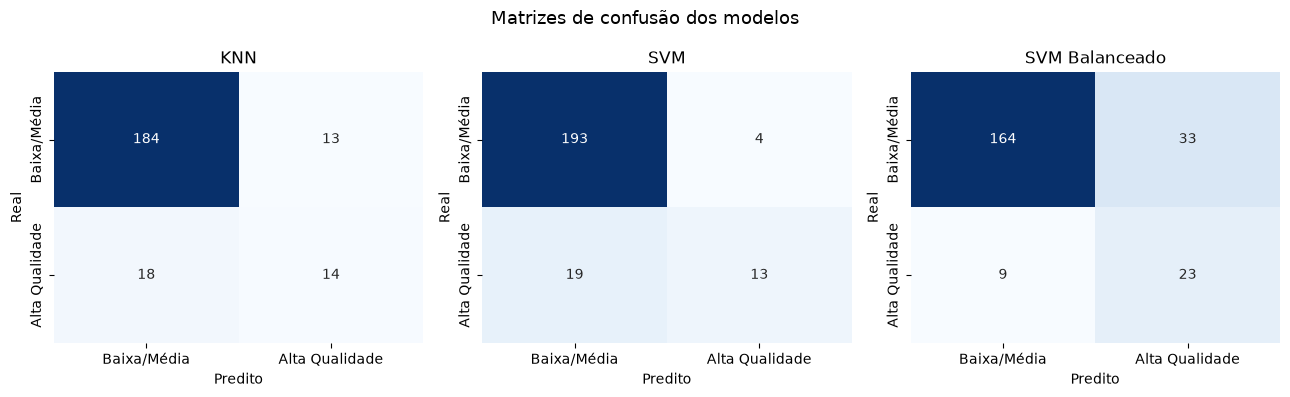

In [24]:
# MATRIZES DE CONFUSÃO DOS MODELOS

from sklearn.metrics import confusion_matrix

matrizes = [
    confusion_matrix(y_test, y_pred_knn),
    confusion_matrix(y_test, y_pred_svm),
    confusion_matrix(y_test, y_pred_svm_balanced)
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, matriz, titulo in zip(
    axes, matrizes, ["KNN", "SVM", "SVM Balanceado"]
):
    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax
    )
    ax.set_title(titulo)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_xticklabels(["Baixa/Média", "Alta Qualidade"])
    ax.set_yticklabels(["Baixa/Média", "Alta Qualidade"], rotation=90)

fig.suptitle("Matrizes de confusão dos modelos", fontsize=13)
plt.tight_layout()
plt.show()


## Interpretação das variáveis

A análise de correlação e a importância das variáveis no modelo indicaram maior destaque para álcool, sulfatos, dióxido de enxofre total, densidade, cloretos e acidez volátil.

Os resultados representam associações observadas nos dados e não permitem afirmar que uma característica isolada seja responsável pela qualidade do vinho.

## Simulação de potencial de melhoria

A análise anterior identificou características associadas à Alta Qualidade. Nesta etapa, vamos testar uma **simulação estatística de cenário**: aproximar, de forma controlada, algumas características dos vinhos de Baixa/Média Qualidade da diferença média observada entre as classes no conjunto de treinamento e verificar como o modelo SVM Balanceado reage.

### Importante

Esta etapa **não demonstra causalidade** e não deve ser interpretada como uma receita de ajuste químico. O objetivo é medir um **potencial de mudança na classificação estimada pelo modelo**. Qualquer intervenção real deve ser validada tecnicamente, sensorialmente e dentro dos limites aplicáveis à produção.

### Critério para as variáveis da simulação

Para evitar escolher variáveis apenas porque apresentaram correlação, serão priorizadas características que combinam dois sinais observados na análise:

1. diferença de direção entre os grupos de qualidade; e
2. importância não negativa na análise de permutation importance do modelo.

Com esse critério, a simulação utiliza:

- **Álcool** — aumento
- **Sulfatos** — aumento
- **Dióxido de enxofre total** — redução
- **Densidade** — redução
- **Cloretos** — redução
- **Acidez volátil** — redução

O **ácido cítrico**, apesar de apresentar associação positiva com a qualidade,
não será usado como variável de intervenção nesta simulação porque sua
importância por permutação no modelo apresentou valor negativo. Isso evita
transformar uma associação descritiva em uma recomendação de intervenção.


In [25]:
# SIMULAÇÃO DE CENÁRIOS DE MELHORIA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Variáveis utilizadas na simulação
variaveis_simulacao = [
    "alcohol",
    "sulphates",
    "total sulfur dioxide",
    "density",
    "chlorides",
    "volatile acidity"
]

# IMPORTANTE:
# O perfil de referência é calculado somente no conjunto de TREINO,
# evitando usar o conjunto de teste para definir os parâmetros da simulação.
treino_sim = X_train.copy()
treino_sim["target"] = y_train.values

medias_treino = treino_sim.groupby("target")[variaveis_simulacao].mean()

# Diferença média entre Alta Qualidade e Baixa/Média Qualidade
delta_alta_vs_baixa = medias_treino.loc[1] - medias_treino.loc[0]

print("DIFERENÇA MÉDIA USADA COMO REFERÊNCIA")
print("=" * 50)
display(
    pd.DataFrame({
        "Média Baixa/Média": medias_treino.loc[0],
        "Média Alta": medias_treino.loc[1],
        "Direção do ajuste": np.where(delta_alta_vs_baixa > 0, "Aumentar", "Reduzir"),
        "Diferença": delta_alta_vs_baixa
    }).style.format({
        "Média Baixa/Média": "{:.4f}",
        "Média Alta": "{:.4f}",
        "Diferença": "{:.4f}"
    })
)

# Base completa de Baixa/Média Qualidade
X_baixa_media = df.loc[df["alta_qualidade"] == 0, variaveis].copy()

# Classificação original da base
predicao_original = svm_balanced.predict(
    scaler.transform(X_baixa_media)
)

# Score original do modelo
score_original = svm_balanced.decision_function(
    scaler.transform(X_baixa_media)
)

# Cenários: fração da diferença média entre os grupos
cenarios = {
    "Conservador (25%)": 0.25,
    "Intermediário (50%)": 0.50,
    "Avançado (75%)": 0.75,
    "Referência (100%)": 1.00
}

resultados_simulacao = []

for nome_cenario, fator in cenarios.items():

    X_simulado = X_baixa_media.copy()

    # Aplica o mesmo fator da diferença média, preservando
    # as demais características originais de cada vinho.
    for coluna in variaveis_simulacao:
        X_simulado[coluna] = (
            X_simulado[coluna]
            + fator * delta_alta_vs_baixa[coluna]
        )

    predicao_simulada = svm_balanced.predict(
        scaler.transform(X_simulado)
    )

    score_simulado = svm_balanced.decision_function(
        scaler.transform(X_simulado)
    )

    novos_alta = (
        (predicao_original == 0)
        & (predicao_simulada == 1)
    ).sum()

    resultados_simulacao.append({
        "Cenário": nome_cenario,
        "Fator aplicado": fator,
        "Baixa/Média antes": int((predicao_original == 0).sum()),
        "Alta Qualidade estimada após": int((predicao_simulada == 1).sum()),
        "Novos casos classificados como Alta": int(novos_alta),
        "% da base Baixa/Média": novos_alta / len(X_baixa_media)
    })

resultados_simulacao = pd.DataFrame(resultados_simulacao)

print("\nRESULTADO DA SIMULAÇÃO")
print("=" * 50)
display(
    resultados_simulacao.style.format({
        "Fator aplicado": "{:.0%}",
        "% da base Baixa/Média": "{:.1%}"
    })
)


DIFERENÇA MÉDIA USADA COMO REFERÊNCIA


,Média Baixa/Média,Média Alta,Direção do ajuste,Diferença
alcohol,10.2701,11.5159,Aumentar,1.2458
sulphates,0.6414,0.7476,Aumentar,0.1062
total sulfur dioxide,46.6747,36.6063,Reduzir,-10.0684
density,0.9968,0.9962,Reduzir,-0.0006
chlorides,0.0867,0.0763,Reduzir,-0.0104
volatile acidity,0.5510,0.3918,Reduzir,-0.1592



RESULTADO DA SIMULAÇÃO


,Cenário,Fator aplicado,Baixa/Média antes,Alta Qualidade estimada após,Novos casos classificados como Alta,% da base Baixa/Média
0,Conservador (25%),25%,817,238,71,7.2%
1,Intermediário (50%),50%,817,342,175,17.8%
2,Avançado (75%),75%,817,473,308,31.3%
3,Referência (100%),100%,817,607,444,45.1%


Vinhos Baixa/Média analisados: 984
Já classificados como Alta pelo modelo antes da simulação: 167
Novos vinhos classificados como Alta no cenário de referência: 444
Percentual potencial entre os 984 vinhos: 45.1%
Score médio antes: -1.0163
Score médio após:  0.2052


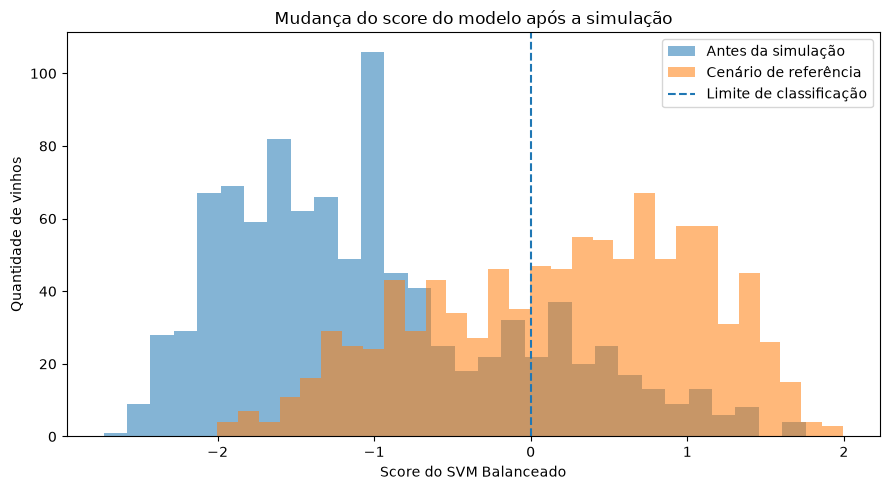

In [26]:
# ANÁLISE DO CENÁRIO DE REFERÊNCIA E LIMITE DE MUDANÇA

# O cenário de referência aplica 100% da diferença média observada
# entre as classes no conjunto de treinamento.
fator_referencia = 1.00

X_referencia = X_baixa_media.copy()

for coluna in variaveis_simulacao:
    X_referencia[coluna] = (
        X_referencia[coluna]
        + fator_referencia * delta_alta_vs_baixa[coluna]
    )

predicao_referencia = svm_balanced.predict(
    scaler.transform(X_referencia)
)
score_referencia = svm_balanced.decision_function(
    scaler.transform(X_referencia)
)

novos_alta_referencia = (
    (predicao_original == 0)
    & (predicao_referencia == 1)
).sum()

print(f"Vinhos Baixa/Média analisados: {len(X_baixa_media):,}")
print(f"Já classificados como Alta pelo modelo antes da simulação: {int((predicao_original == 1).sum()):,}")
print(f"Novos vinhos classificados como Alta no cenário de referência: {int(novos_alta_referencia):,}")
print(f"Percentual potencial entre os 984 vinhos: {novos_alta_referencia / len(X_baixa_media):.1%}")
print(f"Score médio antes: {score_original.mean():.4f}")
print(f"Score médio após:  {score_referencia.mean():.4f}")

# Distribuição do score antes/depois
plt.figure(figsize=(9, 5))
plt.hist(score_original, bins=30, alpha=0.55, label="Antes da simulação")
plt.hist(score_referencia, bins=30, alpha=0.55, label="Cenário de referência")
plt.axvline(0, linestyle="--", linewidth=1.5, label="Limite de classificação")
plt.title("Mudança do score do modelo após a simulação")
plt.xlabel("Score do SVM Balanceado")
plt.ylabel("Quantidade de vinhos")
plt.legend()
plt.tight_layout()
plt.show()


### Como interpretar o resultado

A simulação deve ser lida como uma **estimativa de potencial**, e não como uma previsão de produção.

No cenário de referência, aplicamos aos 984 vinhos de Baixa/Média Qualidade a diferença média observada entre as classes para as variáveis selecionadas e verificamos quantos mudaram de classificação no SVM Balanceado.

O resultado mostra o **tamanho potencial da oportunidade segundo o modelo**, mas não prova que esses vinhos possam ser efetivamente transformados em Alta Qualidade por alterações químicas. O próximo passo, em um contexto real, seria validar individualmente os casos e determinar se os ajustes são tecnicamente viáveis, seguros e sensorialmente aceitáveis.

**Ponto importante:** o cenário de referência é deliberadamente um cenário estatístico de 100% da diferença média. Os cenários de 25%, 50% e 75% permitem visualizar como o resultado muda quando a aproximação ao perfil de Alta Qualidade é menor.

## Conclusão

A análise mostrou que os vinhos de Alta Qualidade representam uma parcela minoritária do conjunto de dados e apresentam diferenças em algumas características físico-químicas em relação às demais amostras.

Entre os modelos avaliados, o SVM com balanceamento das classes apresentou o melhor desempenho para identificar a classe Alta Qualidade, especialmente pelo recall de **78,83%** e ROC-AUC de **88,85%** obtidos na validação cruzada.

A nova simulação acrescenta uma perspectiva de negócio: em vez de apenas identificar quais características estão associadas à qualidade, é possível testar **cenários de aproximação do perfil físico-químico** e medir como a classificação estimada pelo modelo muda.

O resultado da simulação representa uma **oportunidade potencial segundo o modelo**, e não uma garantia de transformação do vinho. O modelo serve como ferramenta de apoio à triagem e à priorização de amostras para investigação técnica, sem substituir avaliações laboratoriais, sensoriais ou decisões de produção.